In [ ]:
import pandas as pd
import numpy as np
import plotly.express as px
from plotly.offline import iplot, init_notebook_mode
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    roc_auc_score, f1_score, confusion_matrix, precision_score, recall_score, average_precision_score, precision_recall_curve
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
import xgboost as xgb
import shap

# Set a global random seed
RANDOM_SEED = 13

# Load the data
sales_df = pd.read_csv('../data/sales_data.csv')

## Exploratory Data Analysis

### Dataset Overview

Column names and types:

In [2]:
sales_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   order_id                60000 non-null  object 
 1   product_id              60000 non-null  object 
 2   product_category        60000 non-null  object 
 3   price                   60000 non-null  float64
 4   is_first_time_customer  60000 non-null  int64  
 5   order_day_of_week       60000 non-null  int64  
 6   returned                60000 non-null  int64  
dtypes: float64(1), int64(3), object(3)
memory usage: 3.2+ MB


The dataset contains 60,000 rows across 7 columns, and no missing values.

### Basic Statistics

In [3]:
sales_df.describe()

,price,is_first_time_customer,order_day_of_week,returned
count,60000.000000,60000.00000,60000.000000,60000.000000
mean,50.514736,0.30080,3.022533,0.089300
std,42.805604,0.45861,1.996178,0.285179
min,6.470000,0.00000,0.000000,0.000000
25%,24.360000,0.00000,1.000000,0.000000
50%,38.320000,0.00000,3.000000,0.000000
75%,61.820000,1.00000,5.000000,0.000000
max,1415.640000,1.00000,6.000000,1.000000


#### Target Variable (`returned`)

In [4]:
return_counts = sales_df.returned.value_counts()
return_pct = sales_df['returned'].value_counts(normalize=True)*100

print(f"Not returned (0): {return_counts[0]:,} ({return_pct[0]:.2f}%)")
print(f"Returned (1): {return_counts[1]:,} ({return_pct[1]:.2f}%)")

Not returned (0): 54,642 (91.07%)
Returned (1): 5,358 (8.93%)


#### Categorical Variables

* `product_category`:

In [5]:
print('Product category distribution:\n')
sales_df.product_category.value_counts()

Product category distribution:



product_category
Engine         12150
Brakes         11935
Filters         9093
Electronics     8953
Suspension      8883
Exhaust         5971
HVAC            3015
Name: count, dtype: int64

In [6]:
print("Return rate by product category:\n")
cat_return_rate = sales_df.groupby('product_category')['returned'].agg(['sum', 'count', 'mean'])
cat_return_rate.columns = ['Returns', 'Total Orders', 'Return Rate']
cat_return_rate = cat_return_rate.sort_values('Return Rate', ascending=False)
print(cat_return_rate)

Return rate by product category:

                  Returns  Total Orders  Return Rate
product_category                                    
Electronics          1416          8953     0.158159
Engine                973         12150     0.080082
HVAC                  238          3015     0.078939
Suspension            701          8883     0.078915
Filters               706          9093     0.077642
Brakes                902         11935     0.075576
Exhaust               422          5971     0.070675


* `order_day_of_week`:

In [7]:
print("\nReturn Rate by Day of Week:\n")
dow_return_rate = sales_df.groupby('order_day_of_week')['returned'].agg(['sum', 'count', 'mean'])
dow_return_rate.columns = ['Returns', 'Total Orders', 'Return Rate']
dow_return_rate = dow_return_rate.sort_values('Return Rate', ascending=False)
print(dow_return_rate)


Return Rate by Day of Week:

                   Returns  Total Orders  Return Rate
order_day_of_week                                    
6                      907          8673     0.104577
5                      888          8620     0.103016
3                      746          8618     0.086563
4                      739          8706     0.084884
1                      701          8436     0.083096
0                      695          8397     0.082768
2                      682          8550     0.079766


* `is_first_time_customer`:

In [8]:
print("\nReturn Rate by Customer Type:\n")
customer_return_rate = sales_df.groupby('is_first_time_customer')['returned'].agg(['sum', 'count', 'mean'])
customer_return_rate.columns = ['Returns', 'Total Orders', 'Return Rate']
customer_return_rate.index = ['Repeat Customer', 'First Time Customer']
customer_return_rate = customer_return_rate.sort_values('Return Rate', ascending=False)
print(customer_return_rate)


Return Rate by Customer Type:

                     Returns  Total Orders  Return Rate
First Time Customer     1982         18048     0.109818
Repeat Customer         3376         41952     0.080473


#### Numerical Variable

* `price`:

In [9]:
print("Price statistics by return status:\n")
price_by_return = sales_df.groupby('returned')['price'].agg(['mean', 'median', 'std', 'min', 'max'])
price_by_return.index = ['Not Returned', 'Returned']
print(price_by_return)

Price statistics by return status:

                   mean  median        std   min      max
Not Returned  50.089180  38.240  41.418695  6.47  1083.75
Returned      54.854653  39.255  54.803686  6.85  1415.64


### Correlation Analysis

In [10]:
num_cols = ['price', 'is_first_time_customer', 'order_day_of_week', 'returned']
corr_matrix = sales_df[num_cols].corr()
print("Correlation with 'returned':\n")
print(corr_matrix['returned'].sort_values(ascending=False))

Correlation with 'returned':

returned                  1.000000
is_first_time_customer    0.047192
price                     0.031748
order_day_of_week         0.027705
Name: returned, dtype: float64


### Plots

* Return rate distribution:

In [11]:
plot_df = sales_df.copy()
plot_df['returned_status'] = plot_df['returned'].map({0: 'Not Returned', 1: 'Returned'})

counts = plot_df['returned_status'].value_counts().reset_index()

fig = px.bar(
    counts,
    x='returned_status', 
    y='count', 
    title='Distribution of Returns', 
    labels={'returned_status': 'Order status', 'count': 'Total number of orders'},
    color='returned_status',
    opacity=0.7
)
fig.show()

This plot clearly shows the imbalance between the classes 0 and 1.

* Order volume by category:

In [12]:
# Bar plot of product category
counts_cat = plot_df['product_category'].value_counts().reset_index()

fig = px.bar(
    counts_cat,
    x='product_category', 
    y='count', 
    title='Order Volume Distribution by Product Category', 
    labels={'count': 'Total number of orders', 'product_category': 'Product category'},
    opacity=0.7
)
fig.show()

* Order volume by day of the week:

In [13]:
# Bar plot of order day of week
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

plot_df['day'] = plot_df['order_day_of_week'].map({
    0: 'Monday', 
    1: 'Tuesday',
    2: 'Wednesday', 
    3: 'Thursday', 
    4: 'Friday', 
    5: 'Saturday',
    6: 'Sunday'
})

counts_dow = plot_df['day'].value_counts().reset_index()

fig = px.bar(
    counts_dow,
    x='day', 
    y='count', 
    title='Order Volume Distribution by Day of the Week', 
    labels={'count': 'Total number of orders', 'day': 'Day of the week'},
    opacity=0.7
)

fig.update_xaxes(categoryorder='array', categoryarray=day_order)

fig.show()

* Order volume by customer type:

In [14]:
# Bar plot of is_first_time_customer
plot_df['ret_cust'] = plot_df['is_first_time_customer'].map({0: 'Repeat customer', 1: 'First time customer'})
counts_ftc = plot_df['ret_cust'].value_counts().reset_index()

fig = px.bar(
    counts_ftc,
    x='ret_cust', 
    y='count', 
    title='Order Volume Distribution by Customer Type', 
    labels={'count': 'Total number of orders', 'ret_cust': 'Customer type'},
    color='ret_cust',
    opacity=0.7
)

fig.show()

* Return rate by product category:

In [15]:
# Bar plot of mean return rate per product category
mrr_cat = plot_df.groupby('product_category')['returned'].mean().reset_index().sort_values(by='returned', ascending=False)

overall_mean = plot_df['returned'].mean()

fig = px.bar(
    mrr_cat,
    x='product_category', 
    y='returned',
    title='Average Return Rate by Product Category', 
    labels={'returned': 'Average return rate', 'product_category': 'Product category'},
    opacity=0.7
)

fig.add_hline(
    y=overall_mean,
    line_dash="dash",
    line_color="red",
    annotation_text=f"Overall avg: {overall_mean:.2f}",
    annotation_position="top right"
)

fig.show()

* Return rate by day of the week:

In [16]:
# Bar plot of mean return rate per day of the week
mrr_dow = plot_df.groupby('day')['returned'].mean().reset_index().sort_values(by='returned', ascending=False)

fig = px.bar(
    mrr_dow,
    x='day', 
    y='returned',
    title='Average Return Rate by Day of the Week', 
    labels={'returned': 'Average return rate', 'day': 'Day of the week'},
    opacity=0.7
)

fig.add_hline(
    y=overall_mean,
    line_dash="dash",
    line_color="red",
    annotation_text=f"Overall avg: {overall_mean:.2f}",
    annotation_position="top left"
)

fig.update_xaxes(categoryorder='array', categoryarray=day_order)

fig.show()

* Return rate by customer type:

In [17]:
# Bar plot of mean return rate by customer type
mrr_cust = plot_df.groupby('ret_cust')['returned'].mean().reset_index().sort_values(by='returned', ascending=False)

fig = px.bar(
    mrr_cust,
    x='ret_cust', 
    y='returned',
    title='Average Return Rate by Customer Type', 
    labels={'returned': 'Average return rate', 'ret_cust': 'Customer type'},
    color='ret_cust',
    opacity=0.7
)

fig.add_hline(
    y=overall_mean,
    line_dash="dash",
    line_color="red",
    annotation_text=f"Overall avg: {overall_mean:.2f}",
    annotation_position="top right"
)

fig.show()

* Price distribution:

In [18]:
# Histogram plot of prices
fig = px.histogram(
    plot_df,
    x='price',
    title='Distribution of Product Prices (Zoomed)',
    nbins=500,
    labels={
        'price': 'Product price ($)',
        'count': 'Number of orders'
    },
    opacity=0.7
)

limit = plot_df['price'].quantile(0.99) # 99th percentile

fig.update_xaxes(
    range=[0, limit*1.05]
)

fig.update_layout(
    yaxis_title='Total number of orders',
    bargap=0.05
)

fig.show()

* Histogram of price distribution by return status:

In [19]:
# Histogram plot of prices per return status
fig = px.histogram(
    plot_df,
    x='price',
    color='returned_status',
    histnorm='probability density',
    title='Price Distribution Segmented by Product Return Status (Zoomed)',
    labels={
        'price': 'Product price ($)',
        'count': 'Density of orders',
        'returned_status': 'Returned status'
    },
    opacity=0.7
)

fig.update_layout(
    bargap=0.05,
    xaxis_title='Product price ($)',
    yaxis_title='Density of orders'
)

fig.update_xaxes(
    range=[0, limit*1.05]
)

fig.show()

* Box plot of price distribution by return status:

In [20]:
# Box plot of prices vs. order status
fig = px.box(
    plot_df,
    x='returned_status',
    y='price',
    title='Price Distribution Segmented by Product Return Status (Zoomed)',
    labels={
        'price': 'Product price ($)', 
        'returned_status': 'Order status'
    },
    color='returned_status'
)

fig.update_yaxes(
    range=[0, limit*1.05], 
    title='Product price ($)'
)

fig.show()


* Correlation heat map:

In [21]:
# Correlation heatmap
fig = px.imshow(
    corr_matrix,
    text_auto=".3f",
    color_continuous_scale="RdBu_r",
    title="Correlation Matrix"
)

fig.show()

## Feature Engineering

### Splitting the Data

In [22]:
# Prediction target
y = sales_df['returned']

# Features
all_features = ['product_category', 'price', 'is_first_time_customer', 'order_day_of_week']
X = sales_df[all_features]

# Split data into two subsets (training plus a temporary set), ensuring balanced class distribution
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    train_size=0.8,
    test_size=0.2,
    random_state=RANDOM_SEED,
    stratify=y
)

# Split the temp data into validation and test sets, ensuring balanced class distribution
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    train_size=0.5,
    test_size=0.5,
    random_state=RANDOM_SEED,
    stratify=y_temp
)

# Combine X and y into a dataframe for feature engineering
train_df = pd.concat([X_train, y_train], axis=1)
val_df = pd.concat([X_val, y_val], axis=1)
test_df = pd.concat([X_test, y_test], axis=1)

# Compute train statistics
cat_return_rate = train_df.groupby('product_category')['returned'].mean()
cat_price_stats = train_df.groupby('product_category')['price'].agg(['mean', 'std'])
overall_price_mean = train_df['price'].mean()
overall_price_std  = train_df['price'].std(ddof=0)

### New Features

* `is_weekend` (binary):

Boolean indicating if order was placed on weekend (days 5 and 6 are Saturday and Sunday). 

In [52]:
# Is weekend
def add_is_weekend(df):
    df = df.copy()
    df['is_weekend'] = df['order_day_of_week'].isin([5, 6]).astype(int)
    return df

train_df = add_is_weekend(train_df)
val_df = add_is_weekend(val_df)
test_df = add_is_weekend(test_df)

* `is_electronic` (binary):

Binary flag for Electronics category.

In [53]:
# Is electronic
def add_is_electronic(df):
    df = df.copy()
    df['is_electronic'] = (df['product_category'] == 'Electronics').astype(int)
    return df

train_df = add_is_electronic(train_df)
val_df = add_is_electronic(val_df)
test_df = add_is_electronic(test_df)

* `is_very_high_price` (binary):

Binary flag for very high price category (> $100).

In [54]:
# Is very high price
def add_is_very_high_price(df, threshold=100):
    df = df.copy()
    df['is_very_high_price'] = (df['price'] > threshold).astype(int)
    return df

train_df = add_is_very_high_price(train_df)
val_df = add_is_very_high_price(val_df)
test_df = add_is_very_high_price(test_df)

* `category_return_rate` (numerical):

Historical return rate by category.

In [55]:
# Category return rate (from train only)
def add_category_return_rate(df, train_df, cat_return_rate=None):
    df = df.copy()
    if cat_return_rate is None:
        cat_return_rate = train_df.groupby('product_category')['returned'].mean()
    global_return_rate = train_df['returned'].mean()
    df['category_return_rate'] = df['product_category'].map(cat_return_rate)
    df['category_return_rate'] = df['category_return_rate'].fillna(global_return_rate)
    return df

train_df = add_category_return_rate(train_df, train_df, cat_return_rate)
val_df   = add_category_return_rate(val_df, train_df, cat_return_rate)
test_df  = add_category_return_rate(test_df, train_df, cat_return_rate)

* `price_zscore_category` (numerical):

Price Z-Score within category.

In [56]:
# Price Z-score category (from train only)
def add_price_zscore_category(df, train_df, cat_price_stats=None, overall_price_mean=None, overall_price_std=None):
    df = df.copy()
    if cat_price_stats is None:
        cat_price_stats = train_df.groupby('product_category')['price'].agg(['mean', 'std'])
    if overall_price_mean is None:
        overall_price_mean = train_df['price'].mean()
    if overall_price_std is None:
        overall_price_std = train_df['price'].std(ddof=0)

    df = df.merge(cat_price_stats, on='product_category', how='left')
    df['mean'] = df['mean'].fillna(overall_price_mean)
    df['std'] = df['std'].replace(0, np.nan).fillna(overall_price_std)
    df['price_zscore_category'] = (df['price'] - df['mean']) / df['std']
    df.drop(columns=['mean', 'std'], inplace=True)
    return df

train_df = add_price_zscore_category(train_df, train_df, cat_price_stats, overall_price_mean, overall_price_std)
val_df   = add_price_zscore_category(val_df, train_df, cat_price_stats, overall_price_mean, overall_price_std)
test_df  = add_price_zscore_category(test_df, train_df, cat_price_stats, overall_price_mean, overall_price_std)


### EDA with Engineered Features

* Correlation of new features with `returned`:

In [28]:
new_features = [
    'is_weekend', 'is_electronic', 'is_very_high_price', 'category_return_rate', 'price_zscore_category'
]

nf_corr = train_df[new_features + ['returned']].corr()['returned'].drop('returned')
nf_corr = nf_corr.sort_values(ascending=False)

print("Correlation of new features with 'returned':\n")
for feat, corr in nf_corr.items():
    print(f"    {feat}: {corr:.4f}")

Correlation of new features with 'returned':

    category_return_rate: 0.1030
    is_electronic: 0.1027
    is_weekend: 0.0331
    price_zscore_category: 0.0275
    is_very_high_price: 0.0188


In [29]:
# Engineered feature correlation with target
fig = px.bar(
    nf_corr.sort_values(ascending=True),
    x='returned',
    title='Correlation of Engineered Features with Returns', 
    labels={'index': 'Engineered feature', 'returned': 'Correlation'},
    opacity=0.7
)

fig.show()

* Return rate by price category:

In [30]:
# Price category
train_df_plot = train_df.copy()
train_df_plot['price_cat'] = pd.cut(
    train_df_plot['price'],
    bins=[0, 25, 50, 100, float('inf')],
    labels=['low', 'medium', 'high', 'very_high']
)

In [31]:
# Return rate by price quartile
price_cat_return = train_df_plot.groupby('price_cat')['returned'].agg(['sum', 'count', 'mean'])

fig = px.bar(
    price_cat_return,
    x=price_cat_return.index,
    y='mean',
    title='Return Rate by Price Category', 
    labels={'price_cat': 'Price category', 'mean': 'Return rate'},
    opacity=0.7
)

fig.add_hline(
    y=overall_mean,
    line_dash="dash",
    line_color="red",
    annotation_text=f"Overall avg: {overall_mean:.2f}",
    annotation_position="top left"
)

fig.show()

C:\Users\aline\AppData\Local\Temp\ipykernel_19244\1111739832.py:2: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



* Return rate on weekdays and weekends:

In [32]:
# Weekend vs. weeday returns
weekend_return = train_df_plot.groupby('is_weekend')['returned'].agg(['sum', 'count', 'mean'])
weekend_return.index = weekend_return.index.map({0: "Weekday", 1: "Weekend"})

fig = px.bar(
    weekend_return,
    x=weekend_return.index,
    y='mean',
    title='Return Rate on Weekdays vs. Weekends', 
    labels={'is_weekend': 'Is weekend', 'mean': 'Return rate'},
    opacity=0.7
)

fig.add_hline(
    y=overall_mean,
    line_dash="dash",
    line_color="red",
    annotation_text=f"Overall avg: {overall_mean:.2f}",
    annotation_position="top left"
)

fig.show()

* Price Z-Score distribution by return status:

In [33]:
# Histogram plot of price Z-Score distribution segmented by return status
fig = px.histogram(
    train_df_plot,
    x='price_zscore_category',
    color='returned',
    histnorm='probability',
    barmode='overlay',
    title='Price Z-Score Distribution Segmented by Product Return Status',
    labels={
        'price': 'Price Z-score per category',
        'count': 'Density of orders',
        'returned': 'Returned status'
    },
    opacity=0.6
)

# Add vertical line at 0 (category mean)
fig.add_vline(
    x=0,
    line_dash="dash",
    line_color="black",
    opacity=0.5,
    annotation_text="category mean",
    annotation_position="top left"
)

fig.update_layout(
    bargap=0.05,
    xaxis_title='Price Z-score per category',
    yaxis_title='Proportion of orders'
)

fig.update_xaxes(range=[-1.2, 5])
fig.update_yaxes(range=[0, 0.05])

fig.show()


## Building the Pipeline, Training and Evaluating

In [34]:
# Update final X and y
X_train_final = train_df.drop(columns=['returned'])
y_train_final = train_df['returned']

X_val_final = val_df.drop(columns=['returned'])
y_val_final = val_df['returned']

X_test_final = test_df.drop(columns=['returned'])
y_test_final = test_df['returned']

### Preprocessing

In [35]:
# Final list of features
cat_features = ['product_category', 'order_day_of_week']
num_features = ['price', 'category_return_rate', 'price_zscore_category']
bin_features = ['is_first_time_customer', 'is_weekend', 'is_electronic', 'is_very_high_price']

# OneHotEncoder
try:
    ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    ohe = OneHotEncoder(handle_unknown='ignore', sparse=False)

# Preprocessing: scale numerical features, one-hot encode categorical features and pass through binary features
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', ohe, cat_features),
        ('bin', 'passthrough', bin_features)
    ]
)

### Model Testing

In [64]:
# Classifiers
LR_classifier = LogisticRegression(
    random_state=RANDOM_SEED, solver='liblinear', class_weight='balanced'
)

RF_classifier = RandomForestClassifier(
    n_estimators=300, random_state=RANDOM_SEED,
    class_weight='balanced', max_depth=6
)

xgb_classifier = xgb.XGBClassifier(
    objective='binary:logistic', n_estimators=300,
    max_depth=4, learning_rate=0.1,
    scale_pos_weight=10,
    subsample=0.8, colsample_bytree=0.8,
    min_child_weight=3,
    random_state=RANDOM_SEED
)

# Build and evaluate pipeline
for name, classifier in {'Logistic Regression': LR_classifier, 'Random Forest Classifier': RF_classifier, 'XGB Classifier': xgb_classifier}.items():
    class_pipeline = Pipeline(
        steps=[
            ('preprocessor', preprocessor),
            ('classifier', classifier)
        ]
    )
    
    class_pipeline.fit(X_train_final, y_train_final)
    class_probabilities = class_pipeline.predict_proba(X_val_final)[:, 1]

    roc_auc_class = roc_auc_score(y_val_final, class_probabilities)
    print(f"ROC AUC Score for {name}: {roc_auc_class}")



ROC AUC Score for Logistic Regression: 0.6100707002141561
ROC AUC Score for Random Forest Classifier: 0.608590864764756
ROC AUC Score for XGB Classifier: 0.5800290845370512


### Hyperparameter Tuning

In [ ]:
# Base model
RF_classifier = RandomForestClassifier(random_state=RANDOM_SEED, class_weight='balanced', n_jobs=-1)

# Hyperparameter space
param_grid = {
    'classifier__n_estimators': [200, 300, 500, 800],
    'classifier__max_depth': [4, 6, 8, 10, None],
    'classifier__min_samples_split': [2, 5, 10, 20],
    'classifier__min_samples_leaf': [1, 2, 5, 10],
    'classifier__max_features': ['sqrt', 'log2', 0.5]
}

# Build the pipeline
full_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', RF_classifier)
    ]
)

# Randomized search
search = RandomizedSearchCV(
    full_pipeline,
    param_distributions=param_grid,
    n_iter=20,
    scoring='average_precision',
    cv=3,
    random_state=RANDOM_SEED,
    n_jobs=-1,
    verbose=2
)

search.fit(X_train_final, y_train_final)

print('Best params: ', search.best_params_)
print('Best PR-AUC (CV): ', search.best_score_)

# Evaluate the best model on validation set
best_model = search.best_estimator_

val_predictions = best_model.predict(X_val_final)
val_probabilities = best_model.predict_proba(X_val_final)[:, 1]

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best params:  {'classifier__n_estimators': 800, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 5, 'classifier__max_features': 'log2', 'classifier__max_depth': 4}
Best PR-AUC (CV):  0.13270775643782495


### Evaluation Metrics

In [37]:
## Calculate evaluation metrics
roc_auc = roc_auc_score(y_val_final, val_probabilities)
pr_auc = average_precision_score(y_val_final, val_probabilities)
f1 = f1_score(y_val_final, val_predictions)
cm = confusion_matrix(y_val_final, val_predictions)
precision = precision_score(y_val_final, val_predictions)
recall = recall_score(y_val_final, val_predictions)

print('Metrics on the validation set')
print(f'ROC-AUC Score: {roc_auc:.4f}')
print(f'PR-AUC Score: {pr_auc:.4f}')
print(f'F1-Score: {f1:.4f}')
print(f'Confusion Matrix:\n{cm}')
print(f'Precision: {precision:.4f}')
print(f'Recall: {recall:.4f}')

Metrics on the validation set
ROC-AUC Score: 0.6119
PR-AUC Score: 0.1362
F1-Score: 0.2147
Confusion Matrix:
[[4295 1169]
 [ 331  205]]
Precision: 0.1492
Recall: 0.3825


## Test Set

In [39]:
# Evaluate the best model on the test set
test_predictions = best_model.predict(X_test_final)
test_probabilities = best_model.predict_proba(X_test_final)[:, 1]

roc_auc_test = roc_auc_score(y_test_final, test_probabilities)
pr_auc_test = average_precision_score(y_test_final, test_probabilities)
f1_test = f1_score(y_test_final, test_predictions)
cm_test = confusion_matrix(y_test_final, test_predictions)
precision_test = precision_score(y_test_final, test_predictions)
recall_test = recall_score(y_test_final, test_predictions)

print('\nMetrics on the test set')
print(f'ROC-AUC Score: {roc_auc_test:.4f}')
print(f'PR-AUC Score: {pr_auc_test:.4f}')
print(f'F1-Score: {f1_test:.4f}')
print(f'Confusion Matrix:\n{cm_test}')
print(f'Precision: {precision_test:.4f}')
print(f'Recall: {recall_test:.4f}')


Metrics on the test set
ROC-AUC Score: 0.6096
PR-AUC Score: 0.1323
F1-Score: 0.2113
Confusion Matrix:
[[4239 1225]
 [ 328  208]]
Precision: 0.1452
Recall: 0.3881


### Feature Importance

* Feature Importance from Random Forest:

In [ ]:
### Feature Importance (Random Forest)
# Extract fitted RF model
rf = best_model.named_steps['classifier']

# Get fitted OneHotEncoder from pipeline
ohe = best_model.named_steps['preprocessor'].named_transformers_['cat']

# Proper categorical feature names
cat_names = ohe.get_feature_names_out(ohe.feature_names_in_)

# Numerical and binary features
num_names = ['price', 'category_return_rate', 'price_zscore_category']
bin_names = ['is_first_time_customer', 'is_weekend', 'is_electronic', 'is_very_high_price']

# Full feature name list
all_feature_names = list(num_names) + list(cat_names) + list(bin_names)

# Feature importances
importances = rf.feature_importances_

feature_importance_df = pd.DataFrame({
    'feature': all_feature_names,
    'importance': importances
}).sort_values(by='importance', ascending=False)

print("\nTop 10 Feature Importances:")
print(feature_importance_df.head(10))

# --- Plotly bar chart ---
import plotly.express as px

fig = px.bar(
    feature_importance_df.head(15),
    x='importance',
    y='feature',
    orientation='h',
    title='Top 15 Feature Importances (Random Forest)',
    labels={'importance': 'Importance', 'feature': 'Feature'},
    opacity=0.7,
    color='importance',
    color_continuous_scale='Viridis'
)
fig.update_layout(yaxis=dict(autorange="reversed"))  # biggest on top
fig.show()



Top 10 Feature Importances:
                         feature  importance
19                 is_electronic    0.234624
4   product_category_Electronics    0.227054
1           category_return_rate    0.207696
17        is_first_time_customer    0.097851
0                          price    0.061450
2          price_zscore_category    0.056944
18                    is_weekend    0.039342
16           order_day_of_week_6    0.012605
15           order_day_of_week_5    0.011234
20            is_very_high_price    0.007325


* Feature Importance from SHAP:

In [84]:
# Extract trained RF model and preprocessor
rf = best_model.named_steps['classifier']
preprocessor = best_model.named_steps['preprocessor']

# Transform validation data
X_val_transformed = preprocessor.transform(X_val_final)

# Build feature names (numerical + OHE + binary)
ohe = preprocessor.named_transformers_['cat']
cat_names = ohe.get_feature_names_out(ohe.feature_names_in_)

num_names = ['price', 'category_return_rate', 'price_zscore_category']
bin_names = ['is_first_time_customer', 'is_weekend', 'is_electronic', 'is_very_high_price']

all_feature_names = list(num_names) + list(cat_names) + list(bin_names)

# Create SHAP explainer
explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_val_transformed)

# Handle binary/multi-class compatibility
if isinstance(shap_values, list):   # old SHAP API
    shap_array = np.array(shap_values[1])  # class=1
    expected_value = explainer.expected_value[1]
else:                               # new SHAP API
    shap_array = np.array(shap_values)
    expected_value = explainer.expected_value

# Fix shape
if shap_array.ndim == 3 and shap_array.shape[2] == 1:
    shap_array = shap_array.squeeze(-1)
elif shap_array.ndim == 3 and shap_array.shape[2] == 2:
    shap_array = shap_array[:, :, 1]   # take class=1 only

# Compute mean absolute SHAP values
shap_importance = np.abs(shap_array).mean(axis=0)

shap_importance_df = pd.DataFrame({
    "feature": all_feature_names,
    "importance": shap_importance
}).sort_values(by="importance", ascending=False)

# Plot with Plotly
fig = px.bar(
    shap_importance_df.head(15),
    x="importance",
    y="feature",
    orientation="h",
    title="Top 15 Features by Mean |SHAP value|",
    color="importance",
    color_continuous_scale="Viridis"
)
fig.update_layout(yaxis=dict(autorange="reversed"))
fig.show()


* SHAP summary plot:

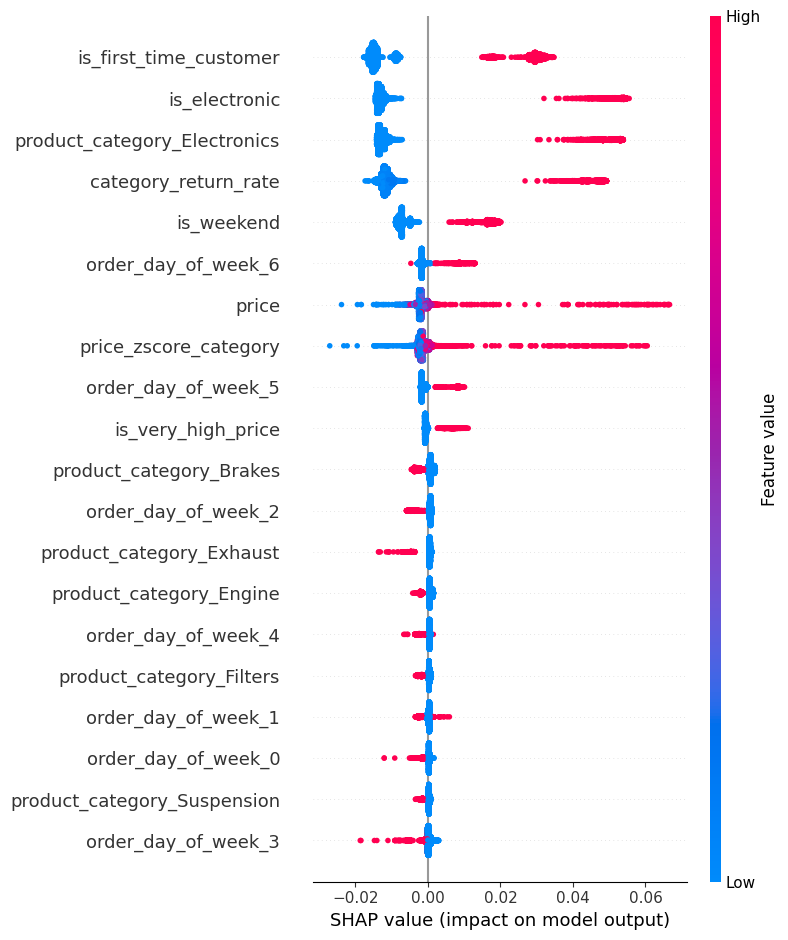

In [80]:
shap.summary_plot(shap_array, X_val_transformed, feature_names=all_feature_names)
